# 08 · Interpretabilidade comparada

Aplica às três arquiteturas da semente 42 um mesmo método de interpretabilidade, o *saliency map*, e à CNN também o Grad-CAM. Os resultados estão no Apêndice C do TCC, Seções C.2 a C.4.

| Método | CNN 1D | BiLSTM | Transformer |
|---|---|---|---|
| *Saliency map* | sim | sim | sim |
| Grad-CAM | sim | não | não |
| Mapa de atenção | não | não | sim (notebook 07) |

O *saliency map* funciona da mesma forma nas três arquiteturas, o que permite compará-las. A medida usada é a mesma do notebook 07: a fração da importância que cai na janela do trânsito, comparada à fração esperada se a importância fosse uniforme. O SHAP, também citado na Fundamentação, não foi aplicado.

In [ ]:
import os, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.backends.cudnn as cudnn
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

DATA_DIR     = '/content/drive/MyDrive/TCC-Exoplanetas'
MODELS_DIR   = f'{DATA_DIR}/modelos'
SEMENTES_DIR = f'{MODELS_DIR}/sementes'
FIG_DIR      = f'{DATA_DIR}/figuras'
os.makedirs(FIG_DIR, exist_ok=True)

device  = 'cuda' if torch.cuda.is_available() else 'cpu'
SEMENTE = 42

d = np.load(f'{DATA_DIR}/dataset.npz')
Xg, Xl, y = d['Xg_test'], d['Xl_test'], d['y_test'].astype(int)
print('teste:', Xg.shape, Xl.shape, '| positivos:', y.mean().round(3))

Mounted at /content/drive
teste: (670, 2001) (670, 201) | positivos: 0.379


## 1. Carregamento dos modelos

In [ ]:
class DoisRamos(nn.Module):
    def __init__(self, fabrica_ramo, p_dropout=0.3):
        super().__init__()
        self.ramo_global = fabrica_ramo(); self.ramo_local = fabrica_ramo()
        d_ = self.ramo_global.out_dim
        self.cabeca = nn.Sequential(
            nn.Linear(2 * d_, 64), nn.ReLU(), nn.Dropout(p_dropout), nn.Linear(64, 1))
    def forward(self, g, l):
        return self.cabeca(torch.cat([self.ramo_global(g), self.ramo_local(l)], 1)).squeeze(-1)

class RamoCNN(nn.Module):
    def __init__(self, base=16):
        super().__init__()
        c1, c2, c3 = base, base * 2, base * 4
        self.net = nn.Sequential(
            nn.Conv1d(1, c1, 5, padding=2), nn.ReLU(), nn.MaxPool1d(5, 2),
            nn.Conv1d(c1, c2, 5, padding=2), nn.ReLU(), nn.MaxPool1d(5, 2),
            nn.Conv1d(c2, c3, 5, padding=2), nn.ReLU(), nn.AdaptiveMaxPool1d(1))
        self.out_dim = c3
    def forward(self, x): return self.net(x).squeeze(-1)

class RamoBiLSTM(nn.Module):
    def __init__(self, hidden=64, camadas=2):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, num_layers=camadas, batch_first=True,
                            bidirectional=True, dropout=0.1 if camadas > 1 else 0.0)
        self.out_dim = 2 * hidden
    def forward(self, x):
        s, _ = self.lstm(x.transpose(1, 2)); return s.mean(dim=1)

def codificacao_posicional(comprimento, dim, device):
    pos = torch.arange(comprimento, device=device).unsqueeze(1).float()
    i   = torch.arange(dim, device=device).unsqueeze(0).float()
    ang = pos / torch.pow(torch.tensor(10000.0, device=device), (2 * (i // 2)) / dim)
    pe = torch.zeros(comprimento, dim, device=device)
    pe[:, 0::2] = torch.sin(ang[:, 0::2]); pe[:, 1::2] = torch.cos(ang[:, 1::2])
    return pe.unsqueeze(0)

class RamoTransformer(nn.Module):
    def __init__(self, d_model=64, nhead=4, camadas=2, stride=8):
        super().__init__()
        self.embed = nn.Conv1d(1, d_model, kernel_size=2 * stride + 1, stride=stride, padding=stride)
        camada = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=128,
                                            dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(camada, camadas); self.out_dim = d_model
    def forward(self, x):
        z = self.embed(x).transpose(1, 2)
        z = z + codificacao_posicional(z.size(1), z.size(2), z.device)
        return self.encoder(z).mean(dim=1)

CLASSES = {'cnn1d': RamoCNN, 'bilstm': RamoBiLSTM, 'transformer': RamoTransformer}
NOMES   = {'cnn1d': 'CNN 1D', 'bilstm': 'BiLSTM', 'transformer': 'Transformer'}

cfg_path, res_path = f'{MODELS_DIR}/config_final.json', f'{MODELS_DIR}/busca_resultados.json'
if os.path.exists(cfg_path):
    cf = json.load(open(cfg_path))
    VENCEDORAS = {s: v['ramo'] for s, v in cf.items()}
else:
    res = json.load(open(res_path)); VENCEDORAS = {}
    for slug in CLASSES:
        c = {k: v for k, v in res.items() if v['slug'] == slug}
        VENCEDORAS[slug] = c[min(c, key=lambda k: c[k]['melhor_val'])]['cfg']['ramo']

MODELOS = {}
for slug, kw in VENCEDORAS.items():
    m = DoisRamos(lambda: CLASSES[slug](**kw)).to(device)
    m.load_state_dict(torch.load(f'{SEMENTES_DIR}/{slug}_seed{SEMENTE}.pt', map_location=device))
    m.eval()
    MODELOS[slug] = m
    print(f'{NOMES[slug]:12s} carregado  {kw}')

CNN 1D       carregado  {'base': 16}
BiLSTM       carregado  {'hidden': 32, 'camadas': 1}
Transformer  carregado  {'d_model': 64, 'camadas': 2}


## 2. *Saliency map*

O *saliency map* é o módulo do gradiente da saída em relação a cada ponto da entrada, ou seja, o quanto uma pequena variação naquele ponto alteraria a decisão do modelo.

O cuDNN não permite calcular gradientes através de camadas LSTM em modo de avaliação. Por isso o cálculo é feito com o cuDNN desativado, o que só o torna mais lento.

In [ ]:
def saliency(modelo, Xg, Xl, lote=32):
    """Devolve (sal_global, sal_local): |d logit / d entrada| para cada exemplo."""
    sg, sl = [], []
    for i in range(0, len(Xg), lote):
        xg = torch.from_numpy(Xg[i:i+lote]).float().unsqueeze(1).to(device).requires_grad_(True)
        xl = torch.from_numpy(Xl[i:i+lote]).float().unsqueeze(1).to(device).requires_grad_(True)
        modelo.zero_grad(set_to_none=True)
        with cudnn.flags(enabled=False):        # necessario para o backward da LSTM em eval
            modelo(xg, xl).sum().backward()
        sg.append(xg.grad.abs().squeeze(1).cpu().numpy())
        sl.append(xl.grad.abs().squeeze(1).cpu().numpy())
    return np.concatenate(sg), np.concatenate(sl)


def normalizar_perfis(p):
    """Normaliza cada exemplo para somar 1 (evita que exemplos de gradiente alto dominem)."""
    soma = p.sum(axis=1, keepdims=True)
    soma[soma == 0] = 1.0
    return p / soma


SAL = {}
for slug, m in MODELOS.items():
    print(f'calculando saliency — {NOMES[slug]} ...', end=' ', flush=True)
    g, l = saliency(m, Xg, Xl)
    SAL[slug] = {'global': normalizar_perfis(g), 'local': normalizar_perfis(l)}
    print('ok')

calculando saliency — CNN 1D ... ok
calculando saliency — BiLSTM ... ok
calculando saliency — Transformer ... ok


## 3. *Saliency* médio na Visão Local

Figura 15 do TCC.

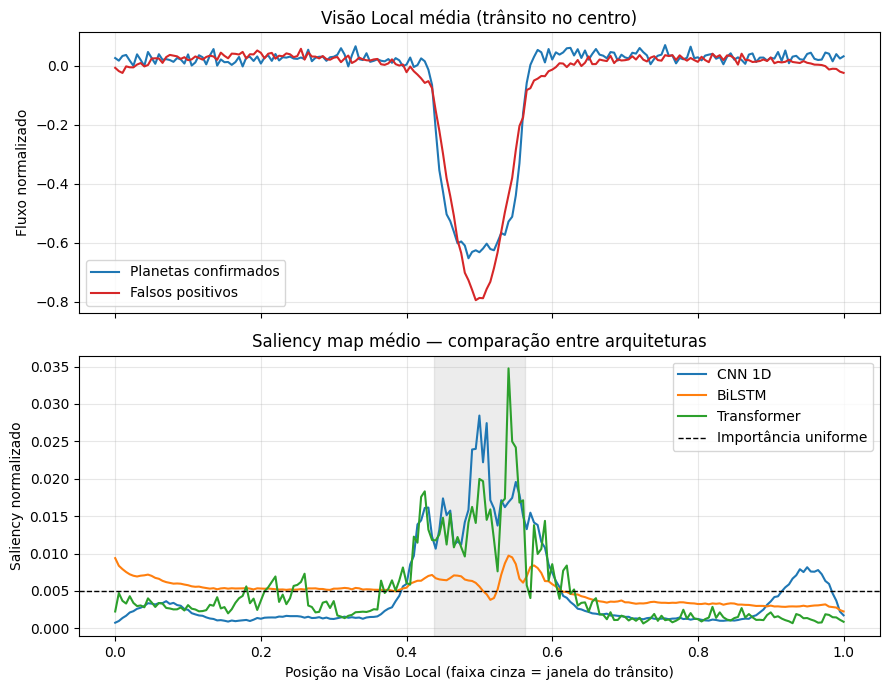

In [ ]:
x_view = np.linspace(0, 1, Xl.shape[1])
fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

ax[0].plot(x_view, Xl[y == 1].mean(0), color='C0', label='Planetas confirmados')
ax[0].plot(x_view, Xl[y == 0].mean(0), color='C3', label='Falsos positivos')
ax[0].set_ylabel('Fluxo normalizado'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title('Visão Local média (trânsito no centro)')

for slug in MODELOS:
    ax[1].plot(x_view, SAL[slug]['local'].mean(0), lw=1.5, label=NOMES[slug])
ax[1].axhline(1 / Xl.shape[1], color='k', ls='--', lw=1, label='Importância uniforme')
ax[1].axvspan(0.5 - 1/16, 0.5 + 1/16, color='gray', alpha=0.15)
ax[1].set_xlabel('Posição na Visão Local (faixa cinza = janela do trânsito)')
ax[1].set_ylabel('Saliency normalizado'); ax[1].legend(); ax[1].grid(alpha=0.3)
ax[1].set_title('Saliency map médio — comparação entre arquiteturas')

plt.tight_layout(); plt.savefig(f'{FIG_DIR}/saliency_comparativo.png', dpi=300); plt.show()

## 4. Concentração no trânsito

A janela do trânsito ocupa 25 dos 201 bins da Visão Local (12,4%). A razão entre a fração observada e essa fração indica quantas vezes a sensibilidade de cada arquitetura se concentra no trânsito em relação a uma distribuição uniforme.

In [ ]:
L = Xl.shape[1]
dentro = (x_view >= 0.5 - 1/16) & (x_view <= 0.5 + 1/16)
esperado = dentro.sum() / L
print(f'Janela do transito: {dentro.sum()}/{L} bins  (esperado sob uniformidade: {esperado:.1%})\n')

linhas = []
for slug in MODELOS:
    p = SAL[slug]['local']
    for classe, nome in [(1, 'Planetas'), (0, 'Falsos positivos')]:
        frac = p[y == classe][:, dentro].sum(axis=1)
        linhas.append({'Arquitetura': NOMES[slug], 'Classe': nome,
                       'Import. no transito': f'{frac.mean():.1%}',
                       'Razao vs uniforme': round(frac.mean() / esperado, 2)})
tab = pd.DataFrame(linhas)
display(tab)
tab.to_csv(f'{DATA_DIR}/interpretabilidade_concentracao.csv', index=False)

Janela do transito: 25/201 bins  (esperado sob uniformidade: 12.4%)



,Arquitetura,Classe,Import. no transito,Razao vs uniforme
0,CNN 1D,Planetas,36.7%,2.95
1,CNN 1D,Falsos positivos,46.7%,3.76
2,BiLSTM,Planetas,21.4%,1.72
3,BiLSTM,Falsos positivos,13.3%,1.07
4,Transformer,Planetas,31.7%,2.55
5,Transformer,Falsos positivos,44.3%,3.56


## 5. Grad-CAM da CNN

O Grad-CAM pondera os mapas de ativação da última camada convolucional pelos gradientes da saída. Aplica-se só à CNN, a única com mapas convolucionais desse tipo no final do ramo.

Na execução final, o Grad-CAM atribuiu ao trânsito menos de 1% da importância e a concentrou na última posição da Visão Local, ao contrário do *saliency map* da mesma rede. A explicação mais provável é o efeito do preenchimento nas bordas, selecionado pelo *pooling* máximo global; por isso, o Grad-CAM não foi usado como evidência na interpretação (Apêndice C do TCC, Seção C.3).

In [ ]:
def grad_cam_local(modelo, Xg, Xl, lote=32):
    ramo = modelo.ramo_local
    alvo = [m for m in ramo.net if isinstance(m, nn.Conv1d)][-1]
    guardado = {}
    h1 = alvo.register_forward_hook(lambda m, i, o: guardado.__setitem__('a', o))
    h2 = alvo.register_full_backward_hook(lambda m, gi, go: guardado.__setitem__('g', go[0]))

    cams = []
    for i in range(0, len(Xg), lote):
        xg = torch.from_numpy(Xg[i:i+lote]).float().unsqueeze(1).to(device)
        xl = torch.from_numpy(Xl[i:i+lote]).float().unsqueeze(1).to(device)
        modelo.zero_grad(set_to_none=True)
        modelo(xg, xl).sum().backward()
        a, g = guardado['a'], guardado['g']              # (B, C, L')
        peso = g.mean(dim=2, keepdim=True)                # (B, C, 1)
        cam = torch.relu((peso * a).sum(dim=1))           # (B, L')
        cams.append(cam.detach().cpu().numpy())
    h1.remove(); h2.remove()
    return np.concatenate(cams)

cam = grad_cam_local(MODELOS['cnn1d'], Xg, Xl)
print('Grad-CAM:', cam.shape, '-> reamostrado para', L, 'bins')

# reamostra para o comprimento da Visao Local
x_cam = np.linspace(0, 1, cam.shape[1])
cam_up = np.stack([np.interp(x_view, x_cam, c) for c in cam])
cam_up = normalizar_perfis(cam_up)

Grad-CAM: (670, 48) -> reamostrado para 201 bins


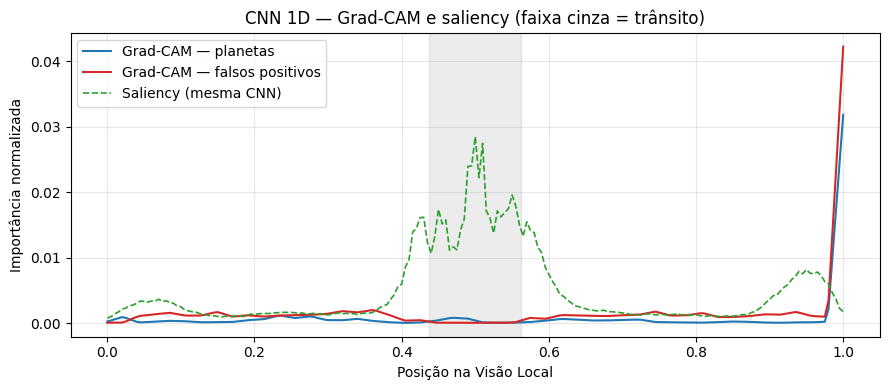

Grad-CAM — Planetas          : 0.9% no transito  (0.07x uniforme)
Grad-CAM — Falsos positivos  : 0.2% no transito  (0.01x uniforme)


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x_view, cam_up[y == 1].mean(0), color='C0', label='Grad-CAM — planetas')
ax.plot(x_view, cam_up[y == 0].mean(0), color='C3', label='Grad-CAM — falsos positivos')
ax.plot(x_view, SAL['cnn1d']['local'].mean(0), color='C2', ls='--', lw=1.2,
        label='Saliency (mesma CNN)')
ax.axvspan(0.5 - 1/16, 0.5 + 1/16, color='gray', alpha=0.15)
ax.set_xlabel('Posição na Visão Local'); ax.set_ylabel('Importância normalizada')
ax.set_title('CNN 1D — Grad-CAM e saliency (faixa cinza = trânsito)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/gradcam_cnn.png', dpi=300); plt.show()

for classe, nome in [(1, 'Planetas'), (0, 'Falsos positivos')]:
    f = cam_up[y == classe][:, dentro].sum(axis=1)
    print(f'Grad-CAM — {nome:18s}: {f.mean():.1%} no transito  ({f.mean()/esperado:.2f}x uniforme)')

## 6. *Saliency* na Visão Global

Figura 17 do TCC. Os picos nas bordas, iguais para planetas e falsos positivos, aparecem na CNN e no Transformer, que usam convoluções com preenchimento, e não na BiLSTM (Apêndice C do TCC, Seção C.4).

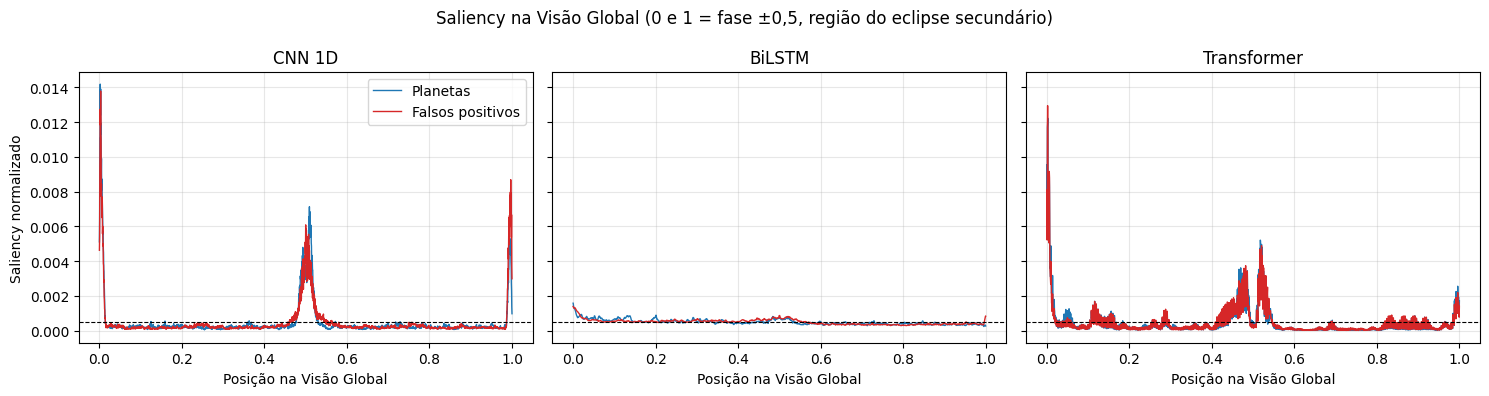

In [ ]:
x_g = np.linspace(0, 1, Xg.shape[1])
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for eixo, slug in zip(ax, MODELOS):
    eixo.plot(x_g, SAL[slug]['global'][y == 1].mean(0), color='C0', lw=1, label='Planetas')
    eixo.plot(x_g, SAL[slug]['global'][y == 0].mean(0), color='C3', lw=1, label='Falsos positivos')
    eixo.axhline(1 / Xg.shape[1], color='k', ls='--', lw=0.8)
    eixo.set_title(NOMES[slug]); eixo.set_xlabel('Posição na Visão Global')
    eixo.grid(alpha=0.3)
ax[0].set_ylabel('Saliency normalizado'); ax[0].legend()
plt.suptitle('Saliency na Visão Global (0 e 1 = fase ±0,5, região do eclipse secundário)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/saliency_global.png', dpi=300); plt.show()

## Limitações

- O *saliency map* mede a sensibilidade local da saída; é ruidoso e não prova que uma região causa a decisão.
- O Grad-CAM é calculado na resolução da última camada convolucional (48 posições) e reamostrado para 201 bins.
- A análise usa só os modelos da semente 42.

Figuras geradas: `saliency_comparativo.png`, `gradcam_cnn.png` e `saliency_global.png`. Tabela: `interpretabilidade_concentracao.csv`.